<a href="https://colab.research.google.com/github/yw646-boop/Yihan_Wang_stats201/blob/main/student_demo/Yihan/Yihan_week03_04_tabarena_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STATS 201 Week 3 · 04 Evaluation

**Question.** What makes a comparison between prediction methods credible?

Start with [TabArena, NeurIPS 2025](https://papers.neurips.cc/paper_files/paper/2025/file/1697e3fb412da11dc9488249f9e7bbc9-Paper-Datasets_and_Benchmarks_Track.pdf), §2.2–2.3 and Figure 4. Each panel compares methods on a specific set of eligible tabular datasets. Find what the two panels hold in common and what changes between them.

In this independent lab, you will apply one benchmark rule from the paper. Compare a baseline and two classifiers on the **same held-out folds**, under the **same metric**. The numerical results below come from a classroom experiment on scikit-learn's bundled datasets. Figure 4 is the published benchmark reading.

**How to work.** In Colab, choose **File → Save a copy in Drive**. Run the cells in order on CPU. First use the defaults. Change one setting and run the indicated cells again. Your table and gallery display inline.

[TabArena reading and discussion guide](https://github.com/sunshineluyao/ml4ss/blob/main/modules/04-evaluation/README.md) · [Week 3 Prediction Colab](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/03-prediction/week03_03_robot_prediction.ipynb)

## 1 · From prediction to evaluation

A prediction method supplies a class or probabilities for a new row. An evaluation supplies the task, the test split, a baseline and a scoring rule. In Figure 4 of TabArena, each eligibility rule determines the set of datasets behind its ranking. The paper uses repeated outer folds, inner validation for tuning, and a metric suited to each task.

In our small exercise, all three methods receive the same five stratified folds. Each model and its preprocessing learn on training rows within a fold. Test rows are scored once for that fitted model. The model settings are fixed. We report the mean of the five fold scores and pair each result with the baseline on the same fold.

For multiclass probability predictions, the fold's log loss is

$$
L_{m,j}=-\frac{1}{|T_j|}\sum_{i\in T_j}\log \widehat p_m(y_i\mid x_i).
$$

Here $T_j$ is the set of test rows in fold $j$. Lower log loss is better. It penalizes confident errors. The alternative, balanced accuracy, averages recall across classes and uses predicted labels. Higher balanced accuracy is better.

**Think before running.** Could two methods have similar label accuracy and very different log loss? What would that tell you about their confidence?

### Evaluation pseudocode and intuition

A fair comparison gives each model the same test cases and the same scoring rules. Here every row takes one turn as test data. Within each fold, each method learns from the same remaining rows. The class-prior baseline supplies a simple reference point for the gain from learning features.

```text
Choose a dataset with features and observed class labels
Create five stratified test folds and reuse them for all methods
FOR each fold
    Reserve its rows for testing
    FOR each method: class prior, logistic regression and random forest
        Start a fresh model and fit it using the other four folds
        Fit any scaling inside the training pipeline
        Predict labels and probabilities on the reserved fold
        Record log loss, balanced accuracy and the number of test rows
    END FOR
END FOR
For the selected metric, average the five scores for each method
Compare each classifier with the baseline within each fold
Plot the observed fold ranges and the paired improvements
```

Stratification keeps the class proportions similar across folds. A paired comparison subtracts two scores from the **same** test cases, so the comparison holds the test set fixed. [Stratified folds documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)

In [ ]:
# Read and run. The datasets are packaged with scikit-learn.
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as InlineImage, display
from sklearn.base import clone
from sklearn.datasets import load_digits, load_wine
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

## 2 · Run matched folds

**Data.** The default Wine data classify a sample into one of three cultivars using numerical measurements. The optional Digits data classify handwritten digits using 64 tabular pixel features. The cell prints row counts, feature counts, and class counts. Each row is one sample. The targets are the provided classes.

**Models.** The class-prior baseline learns class frequencies from the training fold. Logistic regression learns a probability model after scaling each feature within the training fold. Random forest learns an ensemble of trees. scikit-learn supplies the models and folds. pandas assembles the results.

**Your turn.** Keep DATASET = "wine" first. After trying a metric change in §3, you may set DATASET to "digits" and rerun this cell and §3.

In [ ]:
DATASET = "wine"  # "wine" or "digits"
datasets = {"wine": load_wine, "digits": load_digits}
if DATASET not in datasets:
    raise ValueError("Choose wine or digits.")
data = datasets[DATASET]()
X, y = data.data, data.target
classes, counts = np.unique(y, return_counts=True)
print(f"{DATASET.title()} · {len(y)} rows, {X.shape[1]} features, {len(classes)} classes")
print("Rows by class:", dict(zip(classes.tolist(), counts.tolist())))

# Reuse these exact train and test indices for every method.
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=201).split(X, y))
assert sorted(np.concatenate([test for _, test in folds]).tolist()) == list(range(len(y)))
assert all(np.intersect1d(train, test).size == 0 for train, test in folds)

methods = {
    "Class prior": DummyClassifier(strategy="prior"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=201)),
    "Random forest": RandomForestClassifier(n_estimators=80, random_state=201, n_jobs=1),
}
records = []
with threadpool_limits(limits=1):
    for fold, (train, test) in enumerate(folds, 1):
        for name, estimator in methods.items():
            model = clone(estimator).fit(X[train], y[train])
            assert np.array_equal(model.classes_, classes)
            records.append({
                "Fold": fold, "Method": name, "Test rows": len(test),
                "log_loss": log_loss(y[test], model.predict_proba(X[test]), labels=classes),
                "balanced_accuracy": balanced_accuracy_score(y[test], model.predict(X[test])),
            })
results = pd.DataFrame(records)
display(results.round(3))

Wine · 178 rows, 13 features, 3 classes
Rows by class: {0: 59, 1: 71, 2: 48}
    Fold               Method  Test rows  log_loss  balanced_accuracy
0      1          Class prior         36     1.090              0.333
1      1  Logistic regression         36     0.061              1.000
2      1        Random forest         36     0.126              0.976
3      2          Class prior         36     1.090              0.333
4      2  Logistic regression         36     0.048              0.967
5      2        Random forest         36     0.123              1.000
6      3          Class prior         36     1.090              0.333
7      3  Logistic regression         36     0.099              0.976
8      3        Random forest         36     0.186              0.976
9      4          Class prior         35     1.084              0.333
10     4  Logistic regression         35     0.045              1.000
11     4        Random forest         35     0.135              1.000
12     5     

,Fold,Method,Test rows,log_loss,balanced_accuracy
0,1,Class prior,36,1.090,0.333
1,1,Logistic regression,36,0.061,1.000
2,1,Random forest,36,0.126,0.976
3,2,Class prior,36,1.090,0.333
4,2,Logistic regression,36,0.048,0.967
5,2,Random forest,36,0.123,1.000
6,3,Class prior,36,1.090,0.333
7,3,Logistic regression,36,0.099,0.976
8,3,Random forest,36,0.186,0.976
9,4,Class prior,35,1.084,0.333


### Read the dataset and per-fold table

The default Wine run has **178 samples**, **13 input features** and **3 class labels**. The class counts are **59, 71 and 48**, which sum to 178. The Digits option has **1,797 rows**, **64 pixel features** and **10 labels**. `Fold` numbers identify the test splits. Wine has **35 or 36 test rows** per fold. This is the denominator for the mean log loss. Balanced accuracy uses the count within each class before averaging class recalls. The five folds times three methods produce **15 result rows**.

| Metric | Statistical meaning |
|---|---|
| `log_loss` | The mean negative log of the probability assigned to each row's observed class. **Lower is better.** On a single row, assigning its observed class probability 0.80 gives a loss of about 0.223. Assigning it 0.20 gives about 1.609. |
| `balanced_accuracy` | The mean recall across classes. Recall is the fraction of each observed class correctly predicted. **Higher is better.** A method that always predicts one of three classes scores about 0.333 when all three are present in the test fold. |

Read across methods within the same fold. In Wine fold 1, logistic regression's log loss is **0.061** and random forest's is **0.126**, both computed on the same **36** rows. Those scores describe the probabilities the models assigned to the observed classes. The balanced accuracy column uses predicted labels to calculate average class recall. [Log loss documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html) · [Balanced accuracy documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html)

## 3 · Compare means and paired differences

**Your turn.** Run METRIC = "log_loss" first. Change it to "balanced_accuracy" and rerun this cell. Look at the rank and the size of the score gaps for the same set of predictions.

                     Mean test score  Lowest fold  Highest fold  Matched folds
Method                                                                        
Logistic regression            0.063        0.045         0.099              5
Random forest                  0.136        0.111         0.186              5
Class prior                    1.086        1.079         1.090              5


,Mean test score,Lowest fold,Highest fold,Matched folds
Method,,,,
Logistic regression,0.063,0.045,0.099,5
Random forest,0.136,0.111,0.186,5
Class prior,1.086,1.079,1.090,5


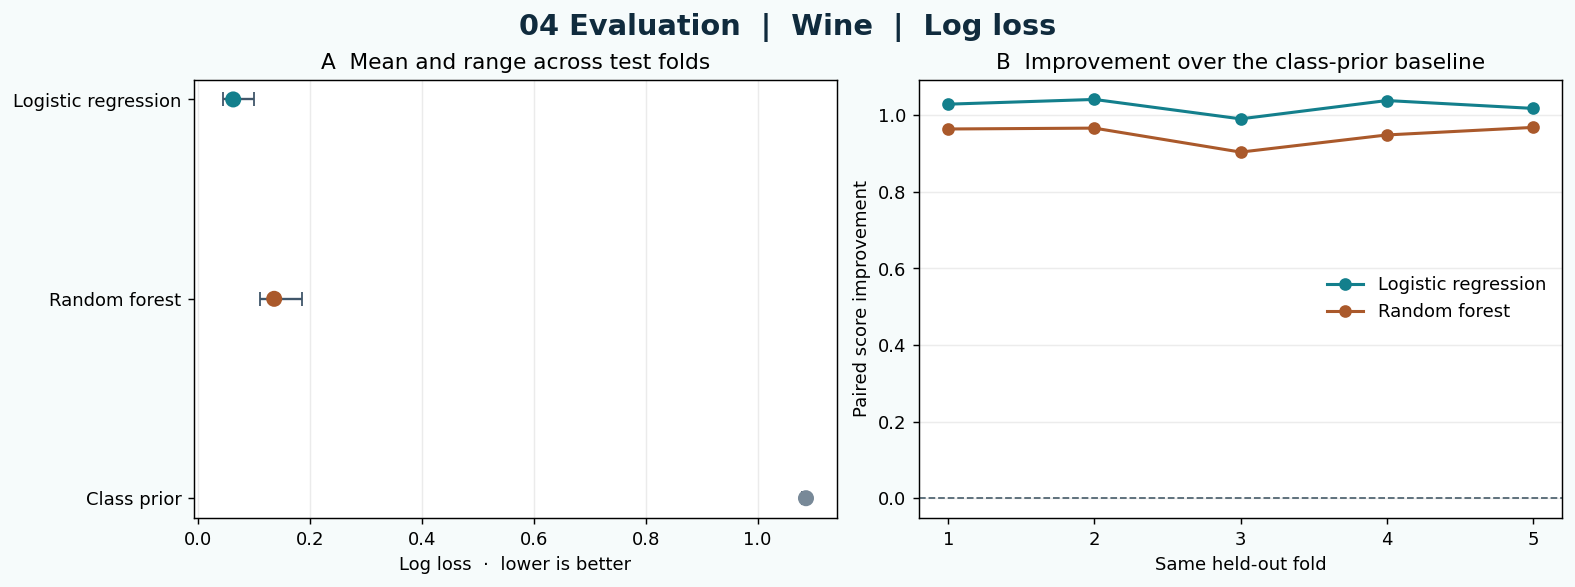

In [ ]:
METRIC = "log_loss"  # "log_loss" or "balanced_accuracy"
direction = {"log_loss": -1, "balanced_accuracy": 1}
titles = {"log_loss": "Log loss", "balanced_accuracy": "Balanced accuracy"}
if METRIC not in direction:
    raise ValueError("Choose log_loss or balanced_accuracy.")

paired = results.pivot(index="Fold", columns="Method", values=METRIC)
assert paired.notna().all().all()
summary = pd.DataFrame({"Mean test score": paired.mean(), "Lowest fold": paired.min(),
                        "Highest fold": paired.max(), "Matched folds": paired.count()})
summary = summary.sort_values("Mean test score", ascending=direction[METRIC] == -1)
display(summary.round(3))
improvement = paired.drop(columns="Class prior").sub(paired["Class prior"],axis=0) * direction[METRIC]

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained", facecolor="#f6fbfb")
colors = {"Class prior":"#788998", "Logistic regression":"#137f8c", "Random forest":"#aa592b"}
labels = summary.index.tolist()
means = summary["Mean test score"].to_numpy()
err = np.stack([means - summary["Lowest fold"], summary["Highest fold"] - means])
a.errorbar(means, labels, xerr=err, fmt="none", color="#40566a", capsize=4, linewidth=1.3)
a.scatter(means, labels, c=[colors[label] for label in labels], s=62, zorder=3)
a.invert_yaxis()
a.set(title="A  Mean and range across test folds",
      xlabel=titles[METRIC] + ("  ·  lower is better" if direction[METRIC] == -1 else "  ·  higher is better"))
a.grid(axis="x", alpha=.25)
for name in improvement:
    b.plot(improvement.index, improvement[name], marker="o", linewidth=1.7, color=colors[name], label=name)
b.axhline(0, color="#536773", linestyle="--", linewidth=1)
b.set(title="B  Improvement over the class-prior baseline",
      xlabel="Same held-out fold", ylabel="Paired score improvement",
      xticks=improvement.index)
b.grid(axis="y", alpha=.23)
b.legend(frameon=False, loc="best")
fig.suptitle(f"04 Evaluation  |  {DATASET.title()}  |  {titles[METRIC]}",
             fontsize=16, fontweight="bold", color="#102b3d")
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
plt.close(fig)
display(InlineImage(data=buffer.getvalue()))

### Read the summary and both gallery panels

| Method | Mean log loss | Lowest log-loss fold | Highest log-loss fold | Mean balanced accuracy |
|---|---:|---:|---:|---:|
| Class prior | 1.086 | 1.079 | 1.090 | 0.333 |
| Logistic regression | 0.063 | 0.045 | 0.099 | 0.984 |
| Random forest | 0.136 | 0.111 | 0.186 | 0.990 |

Each mean gives the five fold scores equal weight. `Lowest fold` and `Highest fold` are the observed minimum and maximum, and `Matched folds` is the number of test folds supplying scores. The table above summarizes the default Wine run. Selecting the alternate metric displays the corresponding column.

**Panel A** uses one dot per method for its mean and horizontal bars for its observed fold range. Training sets overlap across folds, so use the ranges to describe variation among these five scores. **Panel B** puts the fold number on the horizontal axis and the improvement over the class prior on the vertical axis. Zero marks a tie. Positive values favor the classifier. For log loss, improvement is baseline loss minus model loss. For balanced accuracy it is model score minus baseline score. Using the rounded fold 1 log losses, logistic regression's improvement is about $1.090-0.061=1.029$.

## Conclusions and assumptions

**What the results support.** With the fixed Wine folds, logistic regression has the lowest mean log loss and random forest has the highest mean balanced accuracy. The comparison supports different choices depending on whether you care about the probabilities assigned to the observed classes or average class-level recall.

**What the interpretation assumes.** The folds need to represent the types of rows you expect to predict. Stratification balances class proportions, while a project with repeated units or time dependence may need group or time splits. Fit preprocessing inside the training fold and use the same held-out rows for each method. The score must reflect the goal and cost of errors. The five shared folds give a classroom comparison for a fixed dataset and model setup. To choose settings, reserve validation data, then use independent test evidence to assess the selected method. For a wider benchmark, justify the dataset eligibility and metrics before interpreting its ranking.

## 4 · Report one evaluation decision

1. Find one task, split, metric or resource decision in [TabArena](https://papers.neurips.cc/paper_files/paper/2025/file/1697e3fb412da11dc9488249f9e7bbc9-Paper-Datasets_and_Benchmarks_Track.pdf).
2. Compare the two lab metrics for the same dataset. Quote one score or paired difference and explain what it measures.
3. Name one rule you would carry into your project. For example, the robot case may require holding out entire trajectories and reporting Yes recall. Your social science question may require holding out dates, people or groups and choosing a metric that reflects the cost of errors.

**Ed reply.** Give the paper section or figure, your metric and one result from the lab, and your revised evaluation rule.

**Sources.** Erickson et al., *TabArena: A Living Benchmark for Machine Learning on Tabular Data*, NeurIPS 2025 Datasets and Benchmarks. [Paper](https://papers.neurips.cc/paper_files/paper/2025/file/1697e3fb412da11dc9488249f9e7bbc9-Paper-Datasets_and_Benchmarks_Track.pdf) · [Authors' repository](https://github.com/autogluon/tabarena). Dataset and loader documentation for [Wine](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html) and [Digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).